IEEE Metadata analyzer

# Utilidades

## Librerias

In [1]:
# # Colab
# from google.colab import drive
# drive.mount('/content/drive/')

# Basicas
import numpy as np
import seaborn as sns
import pandas as pd
import os, time, pickle, umap, pydot, string, joblib, kaleido, json, re
import xploreapi
from xploreapi import XPLORE

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Ciencia de datos
from scipy.spatial.distance import pdist
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.neighbors import NearestNeighbors

from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.sparse import csr_matrix

# Procesamiento de lenguaje
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# visualizacion
from yellowbrick.cluster import KElbowVisualizer
from wordcloud import WordCloud
import networkx as nx
from IPython.display import Image, display
from graphviz import Digraph

# otros modelos
import gensim, spacy
# Cargar el modelo de spaCy
nlp = spacy.load('en_core_web_sm')

from gensim import corpora
from gensim.models import LsiModel
from gensim.parsing.preprocessing import preprocess_string

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Funciones útiles

In [2]:
def AnalisisNan(data):
  data_nan = 100 - data.isna().sum(axis=0) / len(data) * 100
  data_nan = data_nan.sort_values(ascending=False)
  data_nan = data_nan.round(2)
  colors = sns.color_palette("viridis", len(data_nan))
  plt.figure(figsize=(6, int(0.3 * len(data_nan))))
  plt.barh(data_nan.index, data_nan, color=colors)
  for idx, val in enumerate(data_nan):
    plt.text(val, idx, f'{val}%')
  plt.title('Porcentaje de datos disponibles por columna')
  plt.ylabel('Columna')
  plt.xlabel('% de datos disponibles (no NaN)')
  plt.show()

# Función para eliminar palabras
def remove_custom_words(tokens, remove_words):
    return [word for word in tokens if word not in remove_words]

# Función de lematización y limpieza del texto
def preprocess_text(text):
    # Necesita algunas variables locales
    text = text.lower()  # Poner todo en minusculas
    tokens = word_tokenize(text)  # Tokenización
    tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]  # Eliminar stopwords y puntuación
    tokens = remove_custom_words(tokens, remove_words)  # Eliminar palabras personalizadas
    tokens = [word.replace('-', ' ') for word in tokens] # Eliminar guiones
    tokens = [lemmatizer.lemmatize(word) for word in tokens]  # Lematización
    return ' '.join(tokens)

def RepresentanteCoseno(X):
  similarity_matrix = cosine_similarity(X)
  # Calcular la similitud promedio de cada abstract con todos los demás
  average_similarity = np.mean(similarity_matrix, axis=1)
  # Encontrar el índice del abstract más representativo
  most_representative_index = np.argmax(average_similarity)
  return(most_representative_index)

def NubePalabrasTFIDF(centroide):
  w = 10
  h = 5
  word_freq = centroide.to_dict()
  wordcloud = WordCloud(width=w * 100, height=h * 100,
                        background_color='white',
                        stopwords=None,
                        min_font_size=10).generate_from_frequencies(word_freq)
  plt.figure(figsize=(w, h), facecolor=None)
  plt.imshow(wordcloud, interpolation="bilinear")
  plt.axis("off")
  plt.tight_layout(pad=0)

  plt.show()

# Tema de investigacion

## Busqueda API IEEEXplore

In [3]:
# import constants

# api_key = constants.API_KEY_IEEEXplore

# client = XPLORE(api_key)
# client.abstractText("modular multilevel converter")
# client.maxRecords = 25  # Máximo permitido

# # Obtener el total de registros disponibles
# response = client.callAPI()
# data = json.loads(response)

# total_docs = data.get("total_records", 0)
# print(f"Total de documentos disponibles: {total_docs}")

# # Descargar todos los documentos en lotes de 200
# batch_size = 200
# all_records = []

# for start in range(1, total_docs, batch_size):
#     client.startRecord = start  # Definir el punto de inicio
#     client.resultSetMax = batch_size  # Solicitar el máximo permitido

#     response = client.callAPI()
#     data = json.loads(response)

#     all_records.extend(data.get("articles", []))
#     print(f"Descargados hasta ahora: {len(all_records)}")

# print(f"Total de documentos descargados: {len(all_records)}")


In [4]:
# guardar_datos_api = False
# if guardar_datos_api:
#     data_api = pd.DataFrame(all_records)
#     data_api.to_csv('Data/data_api.csv', index=False)

In [5]:
data = pd.read_csv('Data/data_api.csv')
data.reset_index(inplace=True, drop=True)
print(len(data))
data.drop_duplicates(inplace=True)
print(len(data))

6708
6708


In [6]:
print(data.shape)
display(data.head())
display(data.isna().sum().sort_values())

(6708, 34)


,doi,title,publisher,issn,rank,volume,authors,access_type,content_type,abstract,...,insert_date,index_terms,issue,isbn,conference_location,conference_dates,isbn_formats,partnum,standard_number,standard_status
0,10.1109/OJPEL.2024.3387076,$\beta$-Ga2O3 in Power Electronics Converters:...,IEEE,2644-1314,1,5,{'authors': [{'affiliation': 'Electrical Energ...,CCBY - IEEE is not the copyright holder of thi...,Journals,"In this work, the possibility of using differe...",...,20240410,"{'ieee_terms': {'terms': ['Schottky diodes', '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,10.1109/TPEL.2017.2666847,(2N+1) Selective Harmonic Elimination-PWM for ...,IEEE,1941-0107,2,33,{'authors': [{'affiliation': 'Department of El...,LOCKED,Journals,The performance of modular multilevel converte...,...,20170209,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,1-MW Full-Bridge MMC for High-Current Low-Volt...,VDE,NaN,3,NaN,"{'authors': [{'full_name': 'Roland Unruh', 'au...",LOCKED,Conferences,A full-bridge modular multilevel converter (MM...,...,20200826,{'dynamic_index_terms': {'terms': ['Low Voltag...,NaN,978-3-8007-5245-4,Germany,7-8 July 2020,"{'isbns': [{'format': 'Print ISBN', 'value': '...",NaN,NaN,NaN
3,10.1109/APEC.2019.8721944,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,IEEE,1048-2334,4,NaN,{'authors': [{'affiliation': 'Aero-Power Sci-T...,LOCKED,Conferences,A modular multilevel LLC converter suitable fo...,...,20190527,"{'ieee_terms': {'terms': ['Silicon carbide', '...",NaN,978-1-5386-8331-6,"Anaheim, CA, USA",17-21 March 2019,{'isbns': [{'format': 'Print on Demand(PoD) IS...,NaN,NaN,NaN
4,10.1109/ECCE55643.2024.10861671,"1.5-kV, 1.5-kW, High Voltage Ratio, Bidirectio...",IEEE,2329-3721,5,NaN,{'authors': [{'affiliation': 'Center for High ...,LOCKED,Conferences,Modular multilevel GaN-based isolated DC/DC co...,...,20250210,{'ieee_terms': {'terms': ['Multilevel converte...,NaN,979-8-3503-7607-4,"Phoenix, AZ, USA",20-24 Oct. 2024,{'isbns': [{'format': 'Print on Demand(PoD) IS...,NaN,NaN,NaN


citing_patent_count       0
title                     0
index_terms               0
rank                      0
insert_date               0
authors                   0
access_type               0
content_type              0
abstract                  0
article_number            0
citing_paper_count        0
html_url                  0
publication_title         0
download_count            0
start_page                3
publication_year          3
pdf_url                   3
publisher                 3
publication_number        3
end_page                  7
abstract_url             13
is_number                39
publication_date         94
doi                     166
isbn                   2118
isbn_formats           2118
conference_location    2160
conference_dates       2160
issn                   2793
volume                 4387
issue                  4807
partnum                6415
standard_number        6702
standard_status        6702
dtype: int64

### Filtrar datos utiles

#### Nan

In [7]:
# Eliminar filas que tengan abstract NaN
data.dropna(subset=['abstract'], inplace=True)
display(data.shape)

(6708, 34)

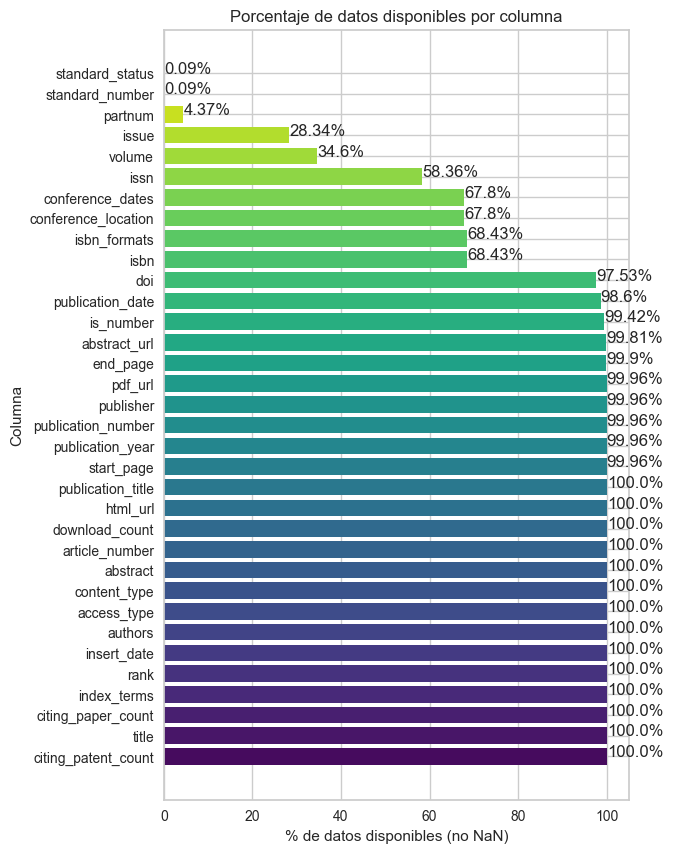

In [8]:
AnalisisNan(data)

In [9]:
fechas = ['publication_date', 'publication_year', 'insert_date']
data[fechas].isna().sum()

publication_date    94
publication_year     3
insert_date          0
dtype: int64

(6708, 7)


title                  object
abstract               object
authors                object
citing_paper_count      int64
citing_patent_count     int64
index_terms            object
insert_date             int64
dtype: object

title                  0
abstract               0
authors                0
citing_paper_count     0
citing_patent_count    0
index_terms            0
insert_date            0
dtype: int64

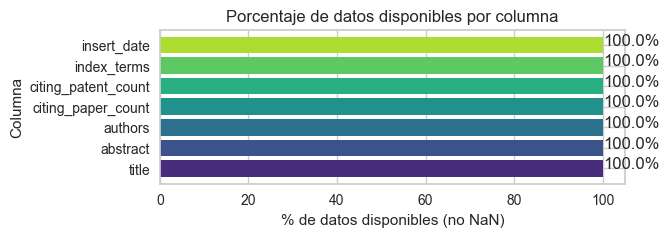

In [10]:
# Atributos importantes
cols2keep = \
['title',
 'abstract',
 'authors',
 'citing_paper_count',
 'citing_patent_count',
 'index_terms',
 'insert_date']

data = data[cols2keep]
print(data.shape)
display(data.dtypes)
display(data.isna().sum().sort_values())

AnalisisNan(data)

In [11]:
# Pasar a minusculas y dejar solo letras
for col in ['title', 'abstract']:
    if data[col].dtype == object:
        data[col] = data[col].str.lower()
        data[col] = data[col].str.replace(r'[^a-z\s]', ' ', regex=True)

In [12]:
data.head()

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210


In [13]:
a = data.duplicated(subset=['title'] , keep='first').sum()
b = data['title'].unique().shape[0]
a, b, a+b

(99, 6609, 6708)

In [14]:
a = data.duplicated(subset=['abstract'] , keep='first').sum()
b = data['abstract'].unique().shape[0]
a, b, a+b

(23, 6685, 6708)

In [15]:
a = data.duplicated(keep='first').sum()
b = data['abstract'].unique().shape[0]
a, b, a+b

(0, 6685, 6685)

In [16]:
# Eliminar abstracts repetidos
# Si hay Abstract repetido, ordenar por:
# Titulo mas largo
# Publication Year mayor
data_unique = data.copy()
data_unique['Title Length'] = data_unique['title'].str.len()
data_unique = data_unique.sort_values(by=['abstract', 'Title Length', 'insert_date'], ascending=[True, False, False])
data_unique = data_unique.drop_duplicates(subset='abstract', keep='first')
# Ordenar segun indice original
data_unique.sort_index(inplace=True)
# Reset index
data_unique.reset_index(drop=True, inplace=True)
# Eliminar columna extra
data_unique.drop(columns=['Title Length'], inplace=True)
# data filtrado
data = data_unique.copy()
display(data.shape)
display(data.head())

(6685, 7)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210


In [17]:
a = data.duplicated(subset=['title'] , keep='first').sum()
b = data['title'].unique().shape[0]
a, b, a+b

(83, 6602, 6685)

In [18]:
idx = data['title'].duplicated(keep='first')
data_rep = data[idx].copy()
data_rep.shape

(83, 7)

In [19]:
sorted(data_rep['title'].value_counts().sort_values().index.tolist(), key=len)

['table of contents',
 'modular multilevel converters',
 'harmonics analysis and simulation of nlm in mmc',
 'the delta configured modular multilevel converter',
 'capacitor selection for modular multilevel converter',
 'a multilevel modular capacitor clamped dc dc converter',
 'a novel reduced switch count multilevel ac ac converter',
 'high power modular multilevel converters with sic jfets',
 'mmc capacitor voltage decoupling and balancing controls',
 'sliding mode control of the modular multilevel converter',
 'control of parallel connected modular multilevel converters',
 'evolution of very high power      mw  medium voltage drives',
 'detailed and averaged models for a     level mmc hvdc system',
 'enhanced equivalent model of the modular multilevel converter',
 'extended controllability of hvdc converters in the vector space',
 'a hybrid modular multilevel converter for solar power integration',
 'accelerated model of modular multilevel converters in pscad emtdc',
 'a bypass lcc

In [20]:
data_rep.loc[data_rep['title'] == 'table of contents', 'abstract'].values

array(['the following topics are dealt with  mppt  solar pv systems  power converters  photovoltaic applications  microgrid control  widebandgap devices  grid converters  telecom power supplies  modulation  electric drives  induction machines  flux switching machines  renewable energy  utility scale battery systems  modular multilevel converters  three phase converter control  ac ac converters  single phase pfc converters  inductive power transfer  electric motors  smart grids  transportation  nonisolated dc dc converters  multiphase converters  dc ac converters  wind energy  grid stability  resonant control  switched capacitor converters  voltage control  synchronous machines  wide band gap power switch modules  dfig based wind systems  wave generation systems  grid connected power converters  off grid power converters  pm machines  energy storage systems  alternative energy systems  single phase ac dc converters  fault diagnostics  machine diagnostics  active power filters  power qua

In [21]:
data = data[data['title'] != 'table of contents'].copy()
data.reset_index(drop=True)
display(data.shape)
data.head()

(6682, 7)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210


#### Palabras clave Abstract

In [22]:
# M2C
mask1 = data['abstract'].str.contains('modular')
mask2 = data['abstract'].str.contains('multilevel')
mask3 = data['abstract'].str.contains('converter')
mask4 = mask1 & mask2 & mask3

mask5 = data['abstract'].str.contains('mmc')
mask6 = data['abstract'].str.contains('m2c')

mask7 = mask4 | mask5 | mask6

# M3C
mask8 = data['abstract'].str.contains('modular')
mask9 = data['abstract'].str.contains('multilevel')
mask10 = data['abstract'].str.contains('matrix')
mask11 = data['abstract'].str.contains('converter')
mask12 = mask8 & mask9 & mask10 & mask11

mask13 = data['abstract'].str.contains('mmmc')
mask14 = data['abstract'].str.contains('m3c')

mask15 = mask12 | mask13 | mask14

# Ambos
# mask7 = data['abstract'].str.contains('modular multilevel converter')
# mask15 = data['abstract'].str.contains('modular multilevel matrix converter')

mask = mask7 | mask15
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

6682

In [23]:
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(6682, 7)

## Analisis exploratorio

In [24]:
print(data.shape)
display(data.dtypes)
display(data.isna().sum().sort_values())

(6682, 7)


title                  object
abstract               object
authors                object
citing_paper_count      int64
citing_patent_count     int64
index_terms            object
insert_date             int64
dtype: object

title                  0
abstract               0
authors                0
citing_paper_count     0
citing_patent_count    0
index_terms            0
insert_date            0
dtype: int64

Artículo con mayor cantidad de citas

In [25]:
max_citas = data['citing_paper_count'].dropna().max()
max_citas = data[data['citing_paper_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['operation  control  and applications of the modular multilevel converter  a review'],
      dtype=object)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
5150,operation control and applications of the mo...,the modular multilevel converter mmc has bee...,{'authors': [{'affiliation': 'School of Electr...,1879,0,"{'ieee_terms': {'terms': ['Voltage control', '...",20140305


Mayor cantidad de citas en patentes

In [26]:
max_citas = data['citing_patent_count'].dropna().max()
max_citas = data[data['citing_patent_count'] == max_citas]
display(max_citas['title'].values)
max_citas

array(['prototype of multiphase modular multilevel converter with   mw power rating and    level output voltage'],
      dtype=object)

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
5533,prototype of multiphase modular multilevel con...,a versatile prototype converter system of the ...,{'authors': [{'affiliation': 'Institute of Pow...,170,31,"{'ieee_terms': {'terms': ['Prototypes', 'Volta...",20050425


Mas antiguos

In [27]:
data.sort_values(by='insert_date').head()

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
4880,multilevel voltage source converters for mediu...,in this paper a brief review of multilevel con...,{'authors': [{'affiliation': 'Ansaldo Ricerche...,10,1,"{'ieee_terms': {'terms': ['Medium voltage', 'V...",20020806
3853,hybrid multilevel power conversion system a c...,use of multilevel inverters is becoming popula...,{'authors': [{'affiliation': 'Department of El...,30,1,"{'ieee_terms': {'terms': ['Power conversion', ...",20020806
3854,hybrid multilevel power conversion system a c...,trends in power semiconductor technology indic...,{'authors': [{'affiliation': 'Department of El...,568,5,"{'ieee_terms': {'terms': ['Power conversion', ...",20020806
954,a high frequency mva h bridge building blo...,this paper proposes a mva h bridge buildin...,{'authors': [{'affiliation': 'Center for Power...,19,4,"{'ieee_terms': {'terms': ['Snubbers', 'Inducto...",20020807
2977,digitally implemented naturally sampled pwm su...,for dynamic closed loop control of a multileve...,{'authors': [{'affiliation': 'School of Inform...,76,0,{'ieee_terms': {'terms': ['Pulse width modulat...,20031110


Publicaciones por año

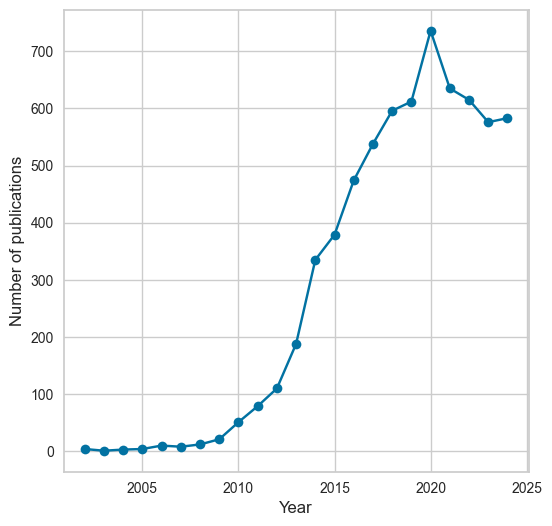

In [28]:
years = data['insert_date'].copy().astype(str).str.extract(r'^(\d{4})').astype(int)

publications_per_year = years[years.values < 2025].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

# plt.title('Number of publications per year', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of publications', fontsize=12)

plt.grid(True)

plt.savefig('Data/Figuras/publications_per_year.pdf')

plt.show()

# Preprocesamiento de texto

## Seleccion de atributos

In [29]:
data

,title,abstract,authors,citing_paper_count,citing_patent_count,index_terms,insert_date
0,beta ga o in power electronics converters ...,in this work the possibility of using differe...,{'authors': [{'affiliation': 'Electrical Energ...,7,0,"{'ieee_terms': {'terms': ['Schottky diodes', '...",20240410
1,n selective harmonic elimination pwm for ...,the performance of modular multilevel converte...,{'authors': [{'affiliation': 'Department of El...,75,0,"{'ieee_terms': {'terms': ['Switches', 'Harmoni...",20170209
2,mw full bridge mmc for high current low volt...,a full bridge modular multilevel converter mm...,"{'authors': [{'full_name': 'Roland Unruh', 'au...",0,0,{'dynamic_index_terms': {'terms': ['Low Voltag...,20200826
3,kv input mhz gan modular multilevel llc co...,a modular multilevel llc converter suitable fo...,{'authors': [{'affiliation': 'Aero-Power Sci-T...,2,0,"{'ieee_terms': {'terms': ['Silicon carbide', '...",20190527
4,kv kw high voltage ratio bidirectio...,modular multilevel gan based isolated dc dc co...,{'authors': [{'affiliation': 'Center for High ...,0,0,{'ieee_terms': {'terms': ['Multilevel converte...,20250210
...,...,...,...,...,...,...,...
6677,zero current switching multilevel modular swit...,this paper presents a quasi resonant technique...,{'authors': [{'affiliation': 'Department of El...,133,19,"{'ieee_terms': {'terms': ['Inductance', 'Capac...",20100907
6678,zero sequence current and voltage control stra...,the ac dc hybrid distribution network hdn is...,{'authors': [{'affiliation': 'Power Electronic...,0,0,"{'ieee_terms': {'terms': ['Circuit faults', 'V...",20250121
6679,zero sequence voltage reduces dc link capacito...,cascaded h bridge converters chbs are a prom...,{'authors': [{'affiliation': 'Paderborn Univer...,2,0,"{'ieee_terms': {'terms': ['Reactive power', 'M...",20221017
6680,zero voltage ride through capability of a tran...,this paper focuses on the zero voltage ride th...,{'authors': [{'affiliation': 'Department of El...,20,0,"{'ieee_terms': {'terms': ['Power quality', 'Vo...",20150615


In [30]:
cols2keep = ['title', 'abstract', 'authors', 'index_terms']
data = data[cols2keep].copy()
data.shape
data.drop_duplicates(subset=cols2keep, inplace=True)
data.shape

(6682, 4)

In [31]:
df = data.copy()

In [34]:
data['authors']

0       {'authors': [{'affiliation': 'Electrical Energ...
1       {'authors': [{'affiliation': 'Department of El...
2       {'authors': [{'full_name': 'Roland Unruh', 'au...
3       {'authors': [{'affiliation': 'Aero-Power Sci-T...
4       {'authors': [{'affiliation': 'Center for High ...
                              ...                        
6677    {'authors': [{'affiliation': 'Department of El...
6678    {'authors': [{'affiliation': 'Power Electronic...
6679    {'authors': [{'affiliation': 'Paderborn Univer...
6680    {'authors': [{'affiliation': 'Department of El...
6681                                      {'authors': []}
Name: authors, Length: 6682, dtype: object

In [ ]:
dic_author = eval(data.iloc[0]['authors'])
display(dic_author.keys())
dic_author

dict_keys(['authors'])

[{'affiliation': 'Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/38234722600',
  'id': 38234722600,
  'full_name': 'Saeed Jahdi',
  'author_order': 1,
  'authorAffiliations': {'authorAffiliation': ['Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/37089212131',
  'id': 37089212131,
  'full_name': 'Akhil S. Kumar',
  'author_order': 2,
  'authorAffiliations': {'authorAffiliation': ['Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Electrical Power group in the School of Engineering, Newcastle University, Newcastle upon Tyne, U.K.',
  'autho

In [43]:
dic_author['authors']

[{'affiliation': 'Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/38234722600',
  'id': 38234722600,
  'full_name': 'Saeed Jahdi',
  'author_order': 1,
  'authorAffiliations': {'authorAffiliation': ['Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/37089212131',
  'id': 37089212131,
  'full_name': 'Akhil S. Kumar',
  'author_order': 2,
  'authorAffiliations': {'authorAffiliation': ['Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Electrical Power group in the School of Engineering, Newcastle University, Newcastle upon Tyne, U.K.',
  'autho

In [33]:
pd.DataFrame(eval(df['authors'][0]))['authors'].tolist()

[{'affiliation': 'Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/38234722600',
  'id': 38234722600,
  'full_name': 'Saeed Jahdi',
  'author_order': 1,
  'authorAffiliations': {'authorAffiliation': ['Electrical Energy Management Group, Department of Electrical Engineering, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.',
  'authorUrl': 'https://ieeexplore.ieee.org/author/37089212131',
  'id': 37089212131,
  'full_name': 'Akhil S. Kumar',
  'author_order': 2,
  'authorAffiliations': {'authorAffiliation': ['Center for Device Thermography and Reliability (CDTR) of School of Physics, University of Bristol, Bristol, U.K.']}},
 {'affiliation': 'Electrical Power group in the School of Engineering, Newcastle University, Newcastle upon Tyne, U.K.',
  'autho

In [31]:
# Todo el preprocesamiento (stopwords, puntuacion, minusculas, lematizacion, etc)
remove_words = ["use", "base", "propose", "present", "method", "system", "paper", "is", "in", "as", "by", "for", "at", "the", "they", "are", "to", "can"]
remove_words = []
for column in data.columns:
    df[column] = df[column].apply(preprocess_text)

In [32]:
df['abstract']

0       work possibility using different generation be...
1       performance modular multilevel converter mmcs ...
2       full bridge modular multilevel converter mmc c...
3       modular multilevel llc converter suitable high...
4       modular multilevel gan based isolated dc dc co...
                              ...                        
6677    paper present quasi resonant technique multile...
6678    ac dc hybrid distribution network hdn facing g...
6679    cascaded h bridge converter chbs promising sol...
6680    paper focus zero voltage ride zvrt capability ...
6681    following topic dealt power semiconductor devi...
Name: abstract, Length: 6682, dtype: object

## Vectorizacion

Tf idf

In [33]:
df_vectorized = df[['abstract']].copy()

# Vocabulario
vocabulary = ' '.join(df_vectorized['abstract']).split(' ')

# Vectorizacion TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1, 1))
X_vectorized = vectorizer.fit_transform(df['abstract'])
words = vectorizer.get_feature_names_out()
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

In [34]:
df_vectorized.columns

Index(['aa', 'aaac', 'aac', 'aacs', 'aam', 'aamc', 'aamcs', 'aammc', 'aavm',
       'ab',
       ...
       'zsc', 'zscc', 'zss', 'zsv', 'zsvc', 'zsvi', 'zt', 'zvrt', 'zvs',
       'zynq'],
      dtype='object', length=10574)

In [35]:
len(words), len(vocabulary)

(10574, 671780)

In [36]:
len(set(words)), len(set(vocabulary))

(10574, 10597)

In [37]:
len(set(words) - set(vocabulary))

0

In [38]:
len(set(vocabulary) - set(words))
set(vocabulary) - set(words)

{'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'z'}

In [39]:
len(data) # Cantidad de papers

6682

In [40]:
# Palabras ordenadas segun puntaje Tfidf
df_vectorized.sum().sort_values()

calculus        0.060103
stuck           0.060103
unimodal        0.060103
suspending      0.064766
denote          0.065303
                 ...    
converter     311.180088
dc            322.949683
control       326.629914
voltage       383.049719
mmc           383.639068
Length: 10574, dtype: float64

In [41]:
# Palabras ordenadas segun cantidad de apariciones
(df_vectorized != 0).sum().sort_values()

signed           1
scddwg           1
granting         1
grand            1
scdsm            1
              ... 
paper         4883
voltage       5262
converter     6680
modular       6682
multilevel    6682
Length: 10574, dtype: int64

# KNN search

In [42]:
X_vectorized.shape, data.shape

((6682, 10574), (6682, 2))

In [43]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine').fit(X_vectorized)

# # Topico "crudo"
# topico = ["the study of artificial intelligence and its impact on society"]
# topico = ["reinforcement learning control modular multilevel matrix converter"]
# topico = ["reinforcement learning control modular power converter"]
# topico = ["physics informed reinforcement learning"]
# topico = ["reinforcement learning"]
# topico = ["control power converter balance capacitor"]
# topico = ["artificial intelligence reinforcement learning control power converter balance capacitor"]
# topico = ['modular multilevel matrix converter']
topico = ["The artificial intelligence, deep learning, reinforcement learning and neural networks in power converters."]
print(topico)

# Preprocesar
topico = [preprocess_text(topico[0])]
print(topico)

# Vectorizar
topico_vec = vectorizer.transform(topico)
print(topico_vec)

# Calcular KNNs
distances_knn, indices_knn = knn.kneighbors(topico_vec.reshape(1, -1))

for i, idx in enumerate(indices_knn[0]):
    display(f"Vecino {i+1}:")
    display(f"Título: {data['title'][idx]}")
    display(f"Abstract: {data['abstract'][idx]}")
    print("-"*40)

['The artificial intelligence, deep learning, reinforcement learning and neural networks in power converters.']
['artificial intelligence deep learning reinforcement learning neural network power converter']
  (0, 535)	0.33553854010962264
  (0, 1802)	0.049973940927062255
  (0, 2178)	0.32173720108577214
  (0, 4775)	0.3658204712182081
  (0, 5202)	0.6275809799509392
  (0, 6242)	0.1719014734778496
  (0, 6245)	0.28541458247050405
  (0, 7121)	0.0753896926837412
  (0, 7839)	0.370167471524316


'Vecino 1:'

'Título: application of neural network controller and policy gradient reinforcement learning on modular multilevel converter  mmc    a proof of concept'

'Abstract: nowadays deep reinforcement learning method has been introduced to power electronic converter control  but the current applications are relatively simple since the converter needing to be controlled has only a few variables  applying the deep reinforcement learning method on the complicated converter with more variables has not been seen yet  this paper shows that the reinforcement learning also has potential to control a complicated modular multilevel converter  mmc   in our method  the capacitor voltages of submodules  sms   arm currents and output currents are directly sent to a neural network controller  and the outputs of the controller are used as the gating signals of the sms directly  the policy gradient  pg  based reinforcement learning algorithm is used without knowing any model information of the mmc  after learning  all the variables in the mmc can be well controlled  i e   the output current can track to the reference  the capacitor voltage of sms can be well ba

----------------------------------------


...

----------------------------------------


'Vecino 100:'

'Título: an improved resnet based method for online assessment of the aging state of mmc sub module capacitors'

'Abstract: submodule capacitor aging is a serious threat to the safe and stable operation of modular multilevel converter  mmc   in this paper  we propose a fast on line assessment method of submodule capacitor aging state based on improved deep residual network  resnet   in this paper  the impact of sub module capacitance aging on the operating characteristics of mmc is analyzed on the established mmc system simulation platform  on this basis  a sub module capacitance switching state dataset is constructed  and the global characteristics of the sub module capacitance aging state are captured by introducing the long range dependent null convolution structure into the resnet algorithm  the experimental results show that the accuracy of this method can reach        compared with existing methods  this method avoids the need for capacitor ageing tests and enables online assessment of the ageing level without the need for additional sampling channels '

----------------------------------------


# Reduccion de dimensionalidad

### PCA

In [44]:
# PCA 2D
X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
df['pca2d_1'] = X_pca_2d[:, 0]
df['pca2d_2'] = X_pca_2d[:, 1]

# PCA 3D
X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
df['pca3d_1'] = X_pca_3d[:, 0]
df['pca3d_2'] = X_pca_3d[:, 1]
df['pca3d_3'] = X_pca_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

### UMAP

In [45]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0)
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0)
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



# Clustering

Elegir cantidad de tópicos

In [46]:
k = 20
clusters = list(range(k))
clusters

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [47]:
# Asignar esto despues en el clustering o el metodo que sea para identificar el topico consultado
# df.loc[indices_knn[0], "cluster_xx"] = k+2

* DBScan no sirve por que los textos son muy similares
* El método del codo puede ser reemplazado por inspección visual


## Clustering jerárquico

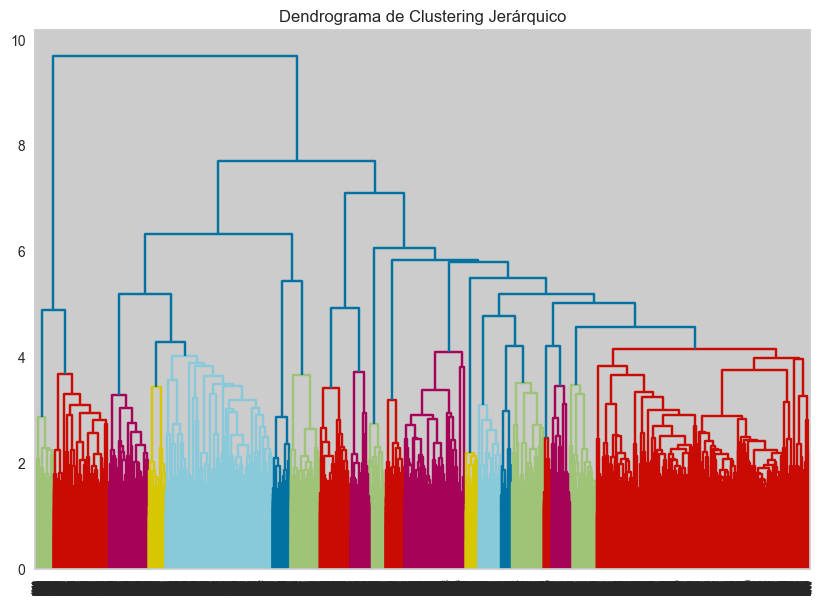

In [48]:
# Z = linkage(df_vectorized, method='ward') # Crear cluster jerarquico con distancia del coseno
# joblib.dump(Z, 'Data/API/hierarchical_cluster_Z.joblib') # Guardar cluster
Z = joblib.load('Data/API/hierarchical_cluster_Z.joblib') # Cargar de cluster hecho de antes
plt.figure(figsize=(10, 7))
plt.title("Dendrograma de Clustering Jerárquico")
dendrogram(Z, color_threshold=4.159)
plt.show()

In [49]:
# Ajustar automaticamente la distancia umbral para tener k clusters

distancia_umbral = 0
clusters_HC = set(range(k+1))
while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 1
distancia_umbral -= 2
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.1
distancia_umbral -= 0.2
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.01
distancia_umbral -= 0.02
clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

while len(clusters_HC) > k:
    clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
    distancia_umbral += 0.001
# distancia_umbral -= 0.002

display(set(clusters_HC))
display(distancia_umbral)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19}

4.159000000000001

In [50]:
# Definir la función para ajustar la distancia umbral
def ajustar_distancia_umbral(Z, k):
    min_dist = 0
    max_dist = max(Z[:, 2])
    
    while min_dist < max_dist:
        mid_dist = (min_dist + max_dist) / 2
        clusters_HC = fcluster(Z, mid_dist, criterion='distance') - 1
        num_clusters = len(set(clusters_HC))
        
        if num_clusters > k:
            min_dist = mid_dist + 1e-5  # Ajustar el límite inferior
        elif num_clusters < k:
            max_dist = mid_dist - 1e-5  # Ajustar el límite superior
        else:
            return clusters_HC, mid_dist
    
    return clusters_HC, mid_dist

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
distancias_umbral = {}

# Obtener distancias umbrales para cada número de clusters en el rango
for k_value in cluster_range:
    clusters_HC, distancia_umbral = ajustar_distancia_umbral(Z, k_value)
    distancias_umbral[k_value] = distancia_umbral
    print(f'Número de clusters: {k_value}, Distancia umbral: {distancia_umbral}')

# Mostrar las distancias umbrales para cada número de clusters
print(distancias_umbral)

Número de clusters: 3, Distancia umbral: 7.273316254836256
Número de clusters: 4, Distancia umbral: 6.667205733599902
Número de clusters: 5, Distancia umbral: 6.212622842672635
Número de clusters: 6, Distancia umbral: 6.061095212363547
Número de clusters: 7, Distancia umbral: 5.833803766899914
Número de clusters: 8, Distancia umbral: 5.75803995174537
Número de clusters: 9, Distancia umbral: 5.454984691127192
Número de clusters: 10, Distancia umbral: 5.303457060818104
Número de clusters: 11, Distancia umbral: 5.198098005368815
Número de clusters: 12, Distancia umbral: 5.151929430509015
Número de clusters: 13, Distancia umbral: 5.000401800199926
Número de clusters: 14, Distancia umbral: 4.924637985045382
Número de clusters: 15, Distancia umbral: 4.848874169890838
Número de clusters: 16, Distancia umbral: 4.6973465395817495
Número de clusters: 17, Distancia umbral: 4.54581890927266
Número de clusters: 18, Distancia umbral: 4.242763648654483
Número de clusters: 19, Distancia umbral: 4.2238

In [51]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, distancias_umbral[k], criterion='distance') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


cluster_HC
19    1837
4      920
11     529
1      481
2      341
15     273
7      265
6      255
18     237
13     196
10     162
0      158
8      157
17     157
5      155
3      146
9      144
12     110
14      95
16      64
Name: count, dtype: int64

## Kmeans

### Metodo del codo

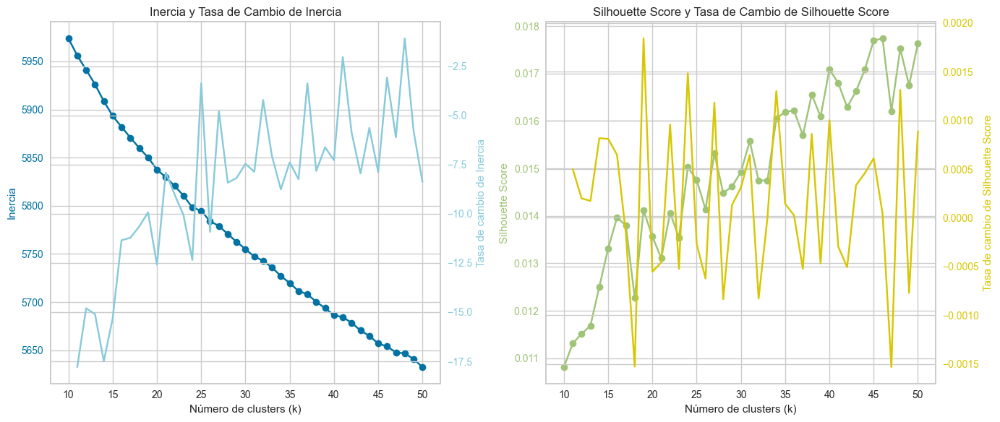

In [52]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X_vectorized)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X_vectorized, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('Data/API/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# Cargar
with open('Data/API/kmeans_metrics.pkl', 'rb') as f:
    metrics = pickle.load(f)
inertia = metrics['inertia']
silhouette_scores = metrics['silhouette_scores']

# Calcular la tasa de cambio para la inercia y el Silhouette Score
delta_inertia = np.diff(inertia)
delta_silhouette = np.diff(silhouette_scores)

# Crear una figura con dos subgráficos (lado a lado)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Graficar la inercia en el primer subgráfico (izquierda)
ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Graficar la tasa de cambio de la inercia en el eje y derecho
ax1_twin = ax1.twinx()
ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
ax1_twin.tick_params(axis='y', labelcolor='c')

# Título y leyenda para el primer gráfico
ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# ax1.legend(loc='best')

# Graficar el Silhouette Score en el segundo subgráfico (derecha)
ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
ax2.set_xlabel('Número de clusters (k)')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

# Graficar la tasa de cambio del Silhouette Score en el eje y derecho
ax2_twin = ax2.twinx()
ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
ax2_twin.tick_params(axis='y', labelcolor='y')

# Título y leyenda para el segundo gráfico
ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# ax2.legend(loc='best')

# Mostrar el gráfico
plt.tight_layout()  # Ajusta el espacio entre los subgráficos
plt.show()

### Clustering final

In [53]:
kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X_vectorized)
df["cluster_KM"] = kmeans.predict(X_vectorized)

print(sorted(df['cluster_KM'].unique()))
df["cluster_KM"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


cluster_KM
0     1154
8      510
16     495
14     466
13     414
9      363
1      345
3      334
4      333
19     317
11     275
17     246
6      212
7      211
10     189
15     183
5      175
12     170
18     166
2      124
Name: count, dtype: int64

Clasificación de un texto

In [54]:
predicted_cluster = kmeans.predict(topico_vec)
print(predicted_cluster)

[0]


## Resultados

In [55]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Elegir tipo de clustering realizado:
* cluster_HC
* cluster_KM

In [56]:
clustering_method = "cluster_KM"

In [57]:
# PCA

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['pca3d_1', 'pca3d_2', 'pca3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['pca2d_1'], 
               y=centroides_2d['pca2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['pca3d_1'], 
                 y=centroides_3d['pca3d_2'], 
                 z=centroides_3d['pca3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

In [58]:
# UMAP

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['umap3d_1', 'umap3d_2', 'umap3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['umap2d_1'], 
               y=centroides_2d['umap2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['umap3d_1'], 
                 y=centroides_3d['umap3d_2'], 
                 z=centroides_3d['umap3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

# Sumarizacion
Nube de palabras en corpus completo y por clusters

### Corpus


Corpus completo: mmc, voltage, control, dc, converter, power, current, system, proposed, fault


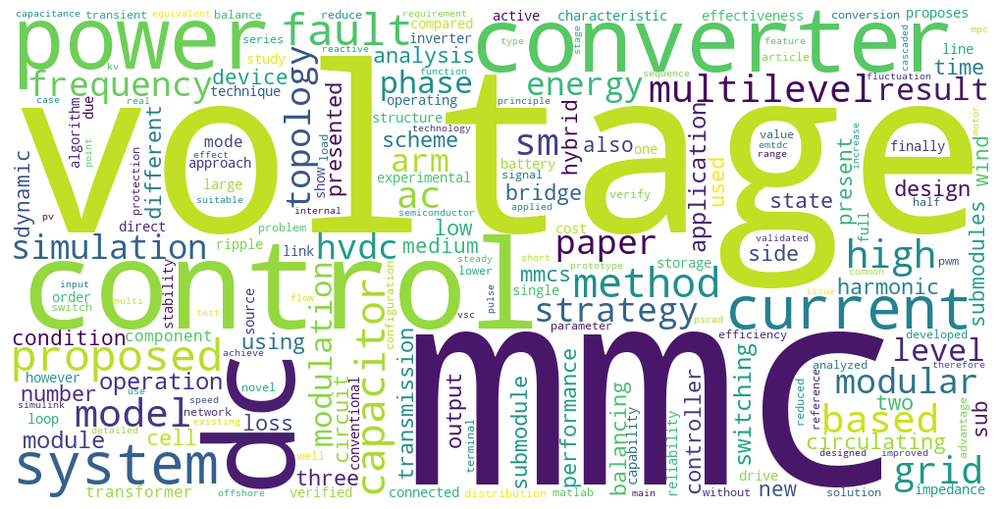

In [59]:
centroide = df_vectorized.mean(axis=0)
print(f'\nCorpus completo: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')

NubePalabrasTFIDF(centroide)

### Clusters

In [60]:
for cluster in clusters:
    cluster_data = df_vectorized[(df[clustering_method] == cluster).values]
    centroide = cluster_data.mean(axis=0)
    print(f'\nCluster {cluster}: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')
    # NubePalabrasTFIDF(centroide)


Cluster 0: power, converter, mmc, voltage, system, topology, energy, multilevel, control, high

Cluster 1: hvdc, system, mmc, transmission, vsc, power, voltage, converter, dc, control

Cluster 2: pv, power, photovoltaic, system, grid, mppt, solar, maximum, dc, control

Cluster 3: circulating, current, control, harmonic, voltage, mmc, arm, controller, component, method

Cluster 4: model, mmc, time, simulation, system, dynamic, transient, accuracy, converter, detailed

Cluster 5: mpc, control, predictive, model, current, mmc, computational, proposed, method, circulating

Cluster 6: drive, motor, speed, frequency, voltage, low, capacitor, machine, ripple, control

Cluster 7: wind, offshore, farm, power, turbine, system, hvdc, mmc, grid, dc

Cluster 8: fault, dc, current, protection, mmc, hvdc, circuit, system, line, pole

Cluster 9: modulation, pwm, level, voltage, carrier, switching, phase, technique, mmc, harmonic

Cluster 10: battery, storage, energy, bess, system, control, power, con

# Documento representativo
En corpus completo y por clusters

## Centroides

In [61]:
def encontrar_mas_cercano_al_centroide(df_vectorized, data):
    centroide = df_vectorized.mean(axis=0)
    distancias = euclidean_distances(df_vectorized, [centroide])
    indice_mas_cercano = np.argmin(distancias)
    texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
    titulo = data.iloc[indice_mas_cercano]['title']
    return titulo, texto_mas_cercano

### Corpus

In [62]:
titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
display(f"Texto mas representativo del corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {texto_mas_cercano}")

'Texto mas representativo del corpus:'

'Título: a control method of dc capacitor voltage in mmc for hvdc system using negative sequence current'

'Abstract: the application of modular multilevel converter  mmc  for high voltage direct current  hvdc  system is expected to enhance power transmission capacity and improve power system stability  to control an mmc hvdc system properly  the ac current  circulating current among arms and submodule  sm  capacitor voltages are considered  in the conventional balance control method of the dc capacitor voltage  the reference value of the circulating current control includes ac component as same frequency as ac grid  in this case  it is difficult to follow the reference value perfectly by proportional integral  pi  controller  this article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current  the validity of the proposed control method is verified by a numerical simulation '

### Clusters

In [63]:
for cluster in clusters:
    cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
    cluster_data = data[df[clustering_method] == cluster]
    titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
    display(f"Cluster {cluster}: Texto mas cercano al centroide")
    display(f"Título: {titulo}")
    display(f"Abstract: {texto_mas_cercano}")

'Cluster 0: Texto mas cercano al centroide'

'Título: hybrid multilevel modular converter for energy storage applications'

'Abstract: multilevel power converters are typically developed for high power applications such as ac drives  energy storage systems  active power filters and compensators  a number of multilevel topologies proposed for these applications  each topology possesses its own advantages and disadvantages and is used in particular area depending on the system requirement  this paper presents a topology of a hybrid modular multilevel converter developed from a cascaded multilevel topology and parallel npc converters technique for energy storage applications  the main purpose of the proposed topology is to reduce the dc link voltage and to preserve acceptable efficiency  lower dc link voltage tends to reduction of the battery costs which reaches     of the all system s cost  an analysis of the energy quality performance and circulating currents is presented  a case study for  mw energy storage is studied to provide figures from comparative analysis '

'Cluster 1: Texto mas cercano al centroide'

'Título: research on control strategy of lcc mmc hybrid hvdc system'

...

'Título: a submodule fault ride through strategy for modular multilevel converters with nearest level modulation'

'Abstract: the modular multilevel converter  mmc  with nearest level modulation  nlm  is widely used in the high voltage applications for low switching frequency and easy implementation  existing literature has not provided a complete submodule  sm  fault ride through scheme for mmc with nlm  in this paper  a strategy including fault detection  localization  redundancy  and recovery is proposed to ensure continuous operation of mmc under igbt open circuit faults conditions  it only requires a few hardware and software resources  the features of mmc and sms with three types of failures are studied  respectively  based on these  the fault detection method is proposed by using a simple hardware circuit  thus high computation complexity is avoided  since current fault localization schemes are limited to mmc with carrier phase shifted pulse width modulation  this paper further proposes a strategy for mmc with nlm to locate the faulty sm and identify the fault type  after this  the fault red

'Cluster 19: Texto mas cercano al centroide'

'Título: a novel modulation method for half bridge based modular multilevel converter under submodule failure with reduced switching frequency'

'Abstract: this paper proposes a novel modulation method for half bridge submodule  sm  based modular multilevel converter  mmc  under faulty sm condition  when a sm is failed  the proper healthy sm is selected and the faulty sm is replaced by the healthy sm in the proposed fault tolerant method  by replacing the faulty sm  the mmc continues its operation as the normal mode  the sm selection is implemented by a novel modulation method and it reduces the switching frequency of all healthy sms  which is the serious drawback of the conventional sorting algorithm  the neutral shift method is applied in order to maintain the balanced three phase line to line voltages during a fundamental period  various simulation studies verify that this post fault strategy guarantees the balanced three phase line to line voltages and currents as well as balancing of sm capacitor voltages without the aid of extra sms '

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [64]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
print("Texto más representativo del corpus:")
print(f"Título: {data['title'].iloc[abstract00]}")
print(f"Abstract: {data['abstract'].iloc[abstract00]}")

Texto más representativo del corpus:
Título: transformation of the energy system in germany   enhancement of system stability by integration of innovative multilevel hvdc in the ac grid
Abstract: globally  deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well  an increasingly liberalized market will encourage trading opportunities to be identified and developed  environmental constraints  such as energy saving  and co  reduction  also play an important role  the loading of existing power systems will further increase  leading to bottlenecks and reliability problems  consequently  we have to deal with an area of conflicts between reliability of supply  environmental sustainability as well as economic efficiency  furthermore  in germany  the transition from well proven energy mix to the new energy transition   energie wende   with large amounts of volatile regenerative energy sources  res   e g  over    gw solar power on

### Clusters

In [65]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: transformation of the energy system in germany   enhancement of system stability by integration of innovative multilevel hvdc in the ac grid'

'Abstract: globally  deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well  an increasingly liberalized market will encourage trading opportunities to be identified and developed  environmental constraints  such as energy saving  and co  reduction  also play an important role  the loading of existing power systems will further increase  leading to bottlenecks and reliability problems  consequently  we have to deal with an area of conflicts between reliability of supply  environmental sustainability as well as economic efficiency  furthermore  in germany  the transition from well proven energy mix to the new energy transition   energie wende   with large amounts of volatile regenerative energy sources  res   e g  over    gw solar power on medium and even low voltage level  in combination with over    gw of wind power  at present   mainly onshore  plus high amounts of offshore wind power in the future     to    gw   long

In [66]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    display(f"Cluster {cluster}: Texto mas representativo")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Cluster 0: Texto mas representativo'

'Título: proper metrological methodologies to avoid severe systematic errors when characterizing high power igbts on the installation field  an introduction'

'Abstract: the exigency of characterizing high power insulated gate bipolar transistors  igbts  directly on site increasingly emerges in field installations hosting multilevel converters that employ such devices by the dozen  when not by hundreds  as it is already the reality for modern modular voltage source hvdc and flexible ac transmission systems  facts   nonetheless  differently from the actualities in permanent laboratories  the typology of the instrumentation rapidly obtainable on the field is often rather restricted by the aspects of logistic  necessary timing of intervention  and ruggedness against the usually harsh environments  commonly  the only specimens realistically expectable at short notice on a field installation are portable curve tracers  cts   portable field oscilloscopes with nonisolated channels  passive voltage probes  current probes based on rogowski coils  portable multimeters  and variable dc power supplies  this paper describes metrological methodologies dev

'Cluster 1: Texto mas representativo'

'Título: transformation of the energy system in germany   enhancement of system stability by integration of innovative multilevel hvdc in the ac grid'

...

'Título: application of artificial intelligence to diagnose faults of grid tied solar power systems'

'Abstract: solar energy has always been an extensively researched field worldwide  one of the key concerns is diagnosing and addressing faults in grid tied solar power systems  solar panels  as vital components of these systems  are prone to various issues including short circuit  open circuit  discoloration and surface cracks  similarly  dc dc or dc ac converters often encounter semiconductor component failures due to prolonged high frequency switching  this paper aims to comprehensively investigate and propose diagnostic methods for grid tied solar power systems  the suggested faults for diagnosis encompass shading  shorts  and mixed faults in pv array  as well as shorts and open circuits in diodes and switches of the dc dc boost converter  additionally  shorts in sub modules of the modular multilevel converter  mmc  are considered  to identify these faults  analysis of i v curve of pv strings  diode voltage signals from the boost converter and three phase output voltage of mmc is co

'Cluster 19: Texto mas representativo'

'Título: enhanced level shifted modulation for a three phase five level modified modular multilevel converter  mmc '

'Abstract: the rapid growth of the penetration level of renewable energy sources  ress  in low voltage  lv  networks increases the research interest in more efficient  compact  reliable  and easily expandable energy conversion systems  the long commutation loops of the existing lv multilevel converters  mlcs   such as active neutral point clamped  anpc  converters  lead to high voltage overshoots induced during switching due to the significant parasitic inductance  modular multilevel converters  mmcs  are gaining an increased interest due to their modularity  flexibility  and short commutation loops also for some lv applications  however  several issues related to the number of components  dc capacitor requirements  and the added complexity need to be considered  this article aims to reduce the five level modified mmc capacitance requirements where the upper and lower submodules  sms  are connected in parallel  this reduction has been achieved using an improved modulation technique by 

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [67]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [68]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: a control method of dc capacitor voltage in mmc for hvdc system using negative sequence current'

'Abstract: the application of modular multilevel converter  mmc  for high voltage direct current  hvdc  system is expected to enhance power transmission capacity and improve power system stability  to control an mmc hvdc system properly  the ac current  circulating current among arms and submodule  sm  capacitor voltages are considered  in the conventional balance control method of the dc capacitor voltage  the reference value of the circulating current control includes ac component as same frequency as ac grid  in this case  it is difficult to follow the reference value perfectly by proportional integral  pi  controller  this article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current  the validity of the proposed control method is verified by a numerical simulation '

### Clusters

In [69]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

'Cluster 0: Texto mas similar a todos en el cluster'

'Título: a phase shifted square wave modulation  ps swm  for modular multilevel converter  mmc  and dc transformer for medium voltage applications'

'Abstract: in this letter  a phase shifted square wave modulation strategy is proposed for modular multilevel converters  mmcs  as well as dc transformers for medium voltage applications  the proposed technique can achieve a smaller cell capacitor size without increasing the total device rating  tdr  and degrading the dc current control capability  the operation principle of the proposed method is presented on an isolated modular multilevel dc dc converter  which consists of an mmc stage and applied as a dc transformer for medium voltage dc grid  the tdr and passive components sizing are derived and compared with those using other modulation methods  finally a downscaled hardware prototype has been built and tested to verify the proposed modulation method '

'Cluster 1: Texto mas similar a todos en el cluster'

'Título: a hybrid modular multilevel converter for solar power integration'

...

'Título: a broad range of speed control of a permanent magnet synchronous motor driven by a modular multilevel tsbc converter'

'Abstract: this paper provides a theoretical and experimental discussion on a modular multilevel triple star bridge cell converter with focus on mitigating the capacitor voltage fluctuation contained in each bridge cell  a new control method proposed in this paper is characterized by properly superimposing both common mode voltage and circulating currents in the whole speed range  moreover  this paper optimizes the amplitude and frequency of the superimposed common mode voltage on the basis of theoretical analysis  thus resulting in minimizing the voltage fluctuation  the optimized control method makes both voltage fluctuation and cluster current amplitude smaller than do the existing methods  experimental waveforms obtained from a three phase downscaled system using a     v     kw     hz  six pole  permanent magnet synchronous motor verify good start up performance from a standstill to the rated speed  keeping both capacitor voltage and cluster current within acceptable levels '

'Cluster 19: Texto mas similar a todos en el cluster'

'Título: a capacitor voltage balancing method in modular multilevel converter using selective mapping'

'Abstract: modular multilevel converter  mmc  is an emerging multilevel inverter in the field of medium and high  voltage applications  balancing the dc capacitor voltage in a module is a challenging task  there are several papers in literature solving the problem  this paper also deals with balancing of capacitor voltages by first sorting the voltages and then driving the switches by comparison result of biased carrier waves and the reference voltages based on the sorted voltages  phase disposition pwm is applied with the voltage balancing technique  matlab simulation was executed to show the effectiveness of the method on a   level mmc using   modules in an arm '

# Grafo de palabras

## Palabras de un abstract especifico

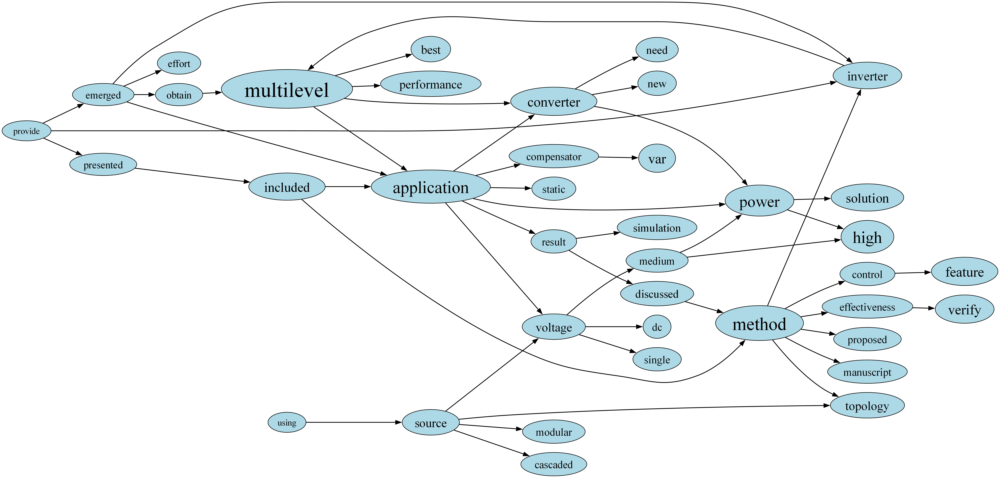

In [70]:
# Obtener el texto del dataframe
texto = df.iloc[1000]["abstract"]

# Procesar el texto con spaCy
doc = nlp(texto)

# Crear grafo dirigido con NetworkX
G = nx.DiGraph()
for token in doc:
    if not token.is_stop and not token.is_punct:
        G.add_node(token.text)
    for child in token.children:
        if not child.is_stop and not child.is_punct:
            G.add_edge(token.text, child.text)

# Calcular importancia con PageRank
pagerank = nx.pagerank(G)

# Crear el grafo con Graphviz
dot = Digraph(format="png")
dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# Agregar nodos con tamaño basado en PageRank
max_pr = max(pagerank.values()) if pagerank else 1
for node, pr in pagerank.items():
    size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
    dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# Agregar aristas
for u, v in G.edges():
    dot.edge(u, v, color="black", penwidth="1.5")

# Renderizar el grafo en un archivo temporal
output_file = "Data/Figuras/grafo"
dot.render(output_file, format="png", cleanup=True)
# Mostrar la imagen en Jupyter Notebook
display(Image(filename=output_file + ".png"))

## Entre clusters